# OIBSIP Data Science – Task 2: Unemployment Analysis with Python

**Objective:** Explore unemployment in India, regional and monthly trends, correlations, and a descriptive pre-/post-COVID comparison.

> **Dataset note:** The commonly used Kaggle dataset provides `Estimated Employed` (a count), unemployment rate, and labour participation rate. It does not provide a direct employment-rate percentage. This notebook derives an *implied employment-to-population ratio* as `labour participation rate × (1 − unemployment rate / 100)` and labels it as derived. Correlation is not causation.

Download the real CSV from [Kaggle – Unemployment in India](https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india) and place it in `data/`. Do not use the synthetic sample for final internship results.

## 1. Import libraries and configure paths

In [3]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
# If Jupyter was launched from the parent folder, use the project directory.
if not (ROOT / "data").exists() and (ROOT / "DataScience-Task2-UnemploymentAnalysis" / "data").exists():
    ROOT = ROOT / "DataScience-Task2-UnemploymentAnalysis"
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
COVID_CUTOFF = pd.Timestamp("2020-03-01")
print("Project folder:", ROOT.resolve())

Project folder: F:\gitproject\OIBSIP\OIBSIP_Task2_Unemployment_Analysis_FIXED\DataScience-Task2-UnemploymentAnalysis


## 2. Locate and load the real dataset
The notebook ignores `sample_unemployment.csv` and selects a real CSV from `data/`.

In [4]:
csv_files = sorted(p for p in DATA_DIR.glob("*.csv") if p.name.lower() != "sample_unemployment.csv")
if not csv_files:
    raise FileNotFoundError(
        "No real CSV found. Download 'Unemployment in India' from Kaggle "
        "and place the CSV inside the data/ folder."
    )
csv_path = csv_files[0]
print("Loading:", csv_path.name)
raw_df = pd.read_csv(csv_path)
print("Raw shape:", raw_df.shape)
display(raw_df.head())
print("Original columns:", raw_df.columns.tolist())

Loading: Unemployment in India.csv
Raw shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


Original columns: ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


## 3. Clean columns, convert types, and inspect missing values

In [5]:
def normalize_name(name):
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

df = raw_df.copy()
df.columns = [normalize_name(c) for c in df.columns]

aliases = {
    "region": ["region", "state", "states"],
    "date": ["date", "month"],
    "unemployment_rate": [
        "estimated_unemployment_rate", "estimated_unemployment_rate_",
        "estimated_unemployment_rate_percent", "unemployment_rate",
        "unemployment_rate_percent"
    ],
    "estimated_employed": ["estimated_employed", "employed", "employment"],
    "labour_participation_rate": [
        "estimated_labour_participation_rate",
        "estimated_labour_participation_rate_",
        "estimated_labour_participation_rate_percent",
        "labour_participation_rate", "labor_participation_rate"
    ],
}
rename = {}
for target, candidates in aliases.items():
    for candidate in candidates:
        if candidate in df.columns:
            rename[candidate] = target
            break
df = df.rename(columns=rename)

required = ["region", "date", "unemployment_rate", "estimated_employed", "labour_participation_rate"]
missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}. Found: {df.columns.tolist()}")

df["region"] = df["region"].astype("string").str.strip()
df["date"] = pd.to_datetime(df["date"].astype(str).str.strip(), dayfirst=True, errors="coerce")
for col in ["unemployment_rate", "estimated_employed", "labour_participation_rate"]:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(",", "", regex=False).str.replace("%", "", regex=False).str.strip(),
        errors="coerce"
    )

print("Shape before cleaning:", df.shape)
print("\nMissing values before cleaning:\n", df.isna().sum())
df = df.dropna(subset=required).copy()
df = df[
    df["region"].ne("")
    & df["unemployment_rate"].between(0, 100)
    & df["labour_participation_rate"].between(0, 100)
    & df["estimated_employed"].ge(0)
].drop_duplicates()
df = df.sort_values("date").reset_index(drop=True)
if df.empty:
    raise ValueError("No valid records remain after cleaning. Check the CSV and its column formats.")

df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()
# Derived proxy: not a directly supplied source column.
df["implied_employment_rate"] = (
    df["labour_participation_rate"] * (1 - df["unemployment_rate"] / 100)
)
print("\nShape after cleaning:", df.shape)
print("\nMissing values after cleaning:\n", df.isna().sum())
print("\nData types:\n", df.dtypes)
display(df.head())

Shape before cleaning: (768, 7)

Missing values before cleaning:
 region                       28
date                         28
frequency                    28
unemployment_rate            28
estimated_employed           28
labour_participation_rate    28
area                         28
dtype: int64

Shape after cleaning: (740, 9)

Missing values after cleaning:
 region                       0
date                         0
frequency                    0
unemployment_rate            0
estimated_employed           0
labour_participation_rate    0
area                         0
month                        0
implied_employment_rate      0
dtype: int64

Data types:
 region                               string
date                         datetime64[us]
frequency                               str
unemployment_rate                   float64
estimated_employed                  float64
labour_participation_rate           float64
area                                    str
month             

,region,date,frequency,unemployment_rate,estimated_employed,labour_participation_rate,area,month,implied_employment_rate
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019-05-01,41.661740
1,Telangana,2019-05-31,Monthly,2.23,11053353.0,61.74,Rural,2019-05-01,60.363198
2,Tamil Nadu,2019-05-31,Monthly,0.97,15844698.0,49.44,Rural,2019-05-01,48.960432
3,Rajasthan,2019-05-31,Monthly,4.03,15226005.0,38.52,Rural,2019-05-01,36.967644
4,Punjab,2019-05-31,Monthly,9.17,6088547.0,44.79,Rural,2019-05-01,40.682757


## 4. Region-wise average unemployment rate
Each bar represents the mean of the available observations for a region. Regional coverage and the observation period affect comparisons.

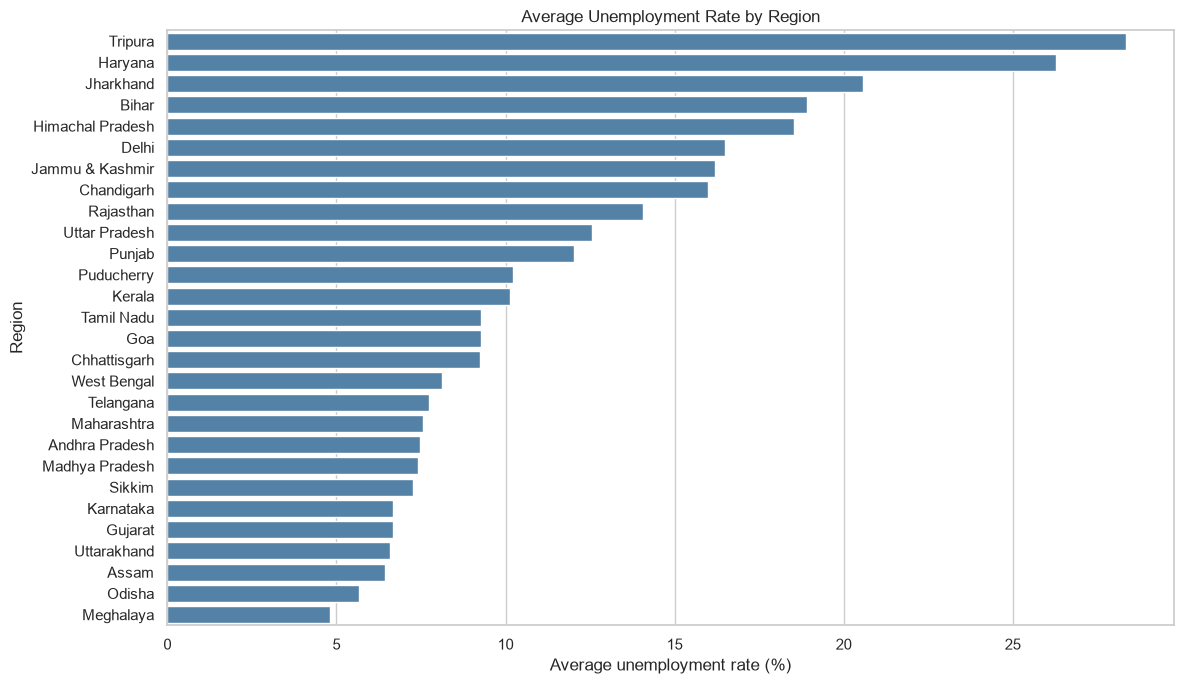

,region,unemployment_rate
24,Tripura,28.350357
8,Haryana,26.283214
11,Jharkhand,20.585000
2,Bihar,18.918214
9,Himachal Pradesh,18.540357
5,Delhi,16.495357
10,Jammu & Kashmir,16.188571
3,Chandigarh,15.991667
20,Rajasthan,14.058214
25,Uttar Pradesh,12.551429


Observation: The regions at the top have the highest average unemployment rates over the dataset's observation period. Check date coverage before interpreting the ranking.


In [6]:
region_avg = (
    df.groupby("region", as_index=False)["unemployment_rate"]
      .mean()
      .sort_values("unemployment_rate", ascending=False)
)
plt.figure(figsize=(12, 7))
sns.barplot(data=region_avg, x="unemployment_rate", y="region", color="steelblue")
plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average unemployment rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "region_average_unemployment.png", dpi=150)
plt.show()
display(region_avg.head(10))
print("Observation: The regions at the top have the highest average unemployment rates over the dataset's observation period. Check date coverage before interpreting the ranking.")

## 5. Month-wise unemployment trend
Monthly means make it easier to identify broad changes and unusual spikes over time.

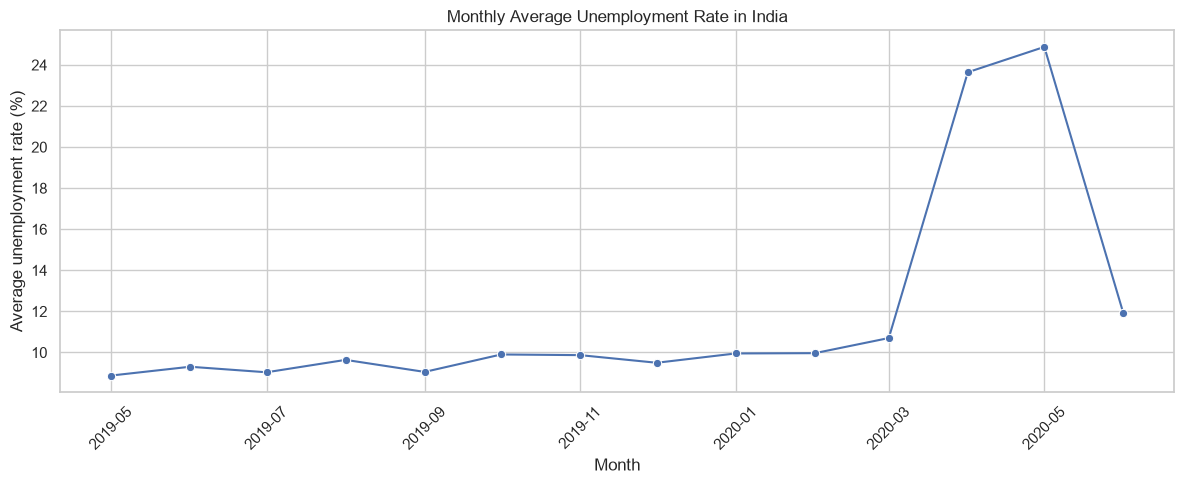

Observation: The highest monthly average in this dataset is 24.88% in May 2020. This is a dataset-level result.


In [7]:
monthly = df.groupby("month", as_index=False)["unemployment_rate"].mean()
plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly, x="month", y="unemployment_rate", marker="o")
plt.title("Monthly Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average unemployment rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "monthly_unemployment_trend.png", dpi=150)
plt.show()
peak = monthly.loc[monthly["unemployment_rate"].idxmax()]
print(f"Observation: The highest monthly average in this dataset is {peak['unemployment_rate']:.2f}% in {peak['month']:%B %Y}. This is a dataset-level result.")

## 6. Time-series comparison for at least three regions
The three regions with the largest number of distinct observed months are selected automatically, reducing the risk of choosing regions with very sparse data.

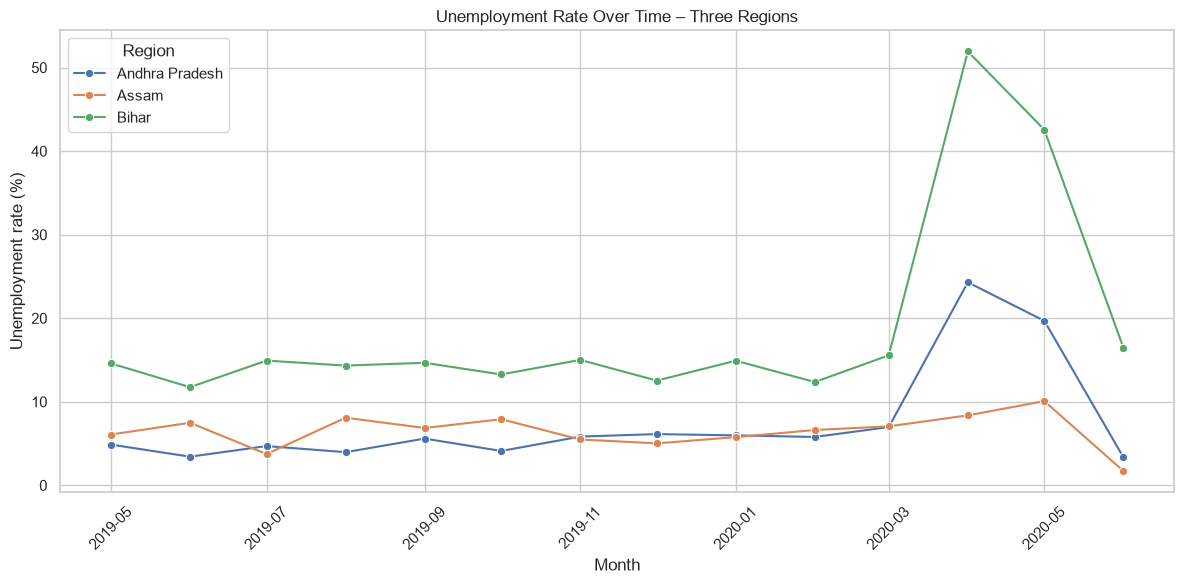

Regions selected: Andhra Pradesh, Assam, Bihar
Observation: Compare the direction and timing of changes across these regions. A rise or fall should be interpreted with each region's data coverage in mind.


In [8]:
region_coverage = df.groupby("region")["date"].nunique().sort_values(ascending=False)
selected_regions = region_coverage.head(3).index.tolist()
trend3 = (
    df[df["region"].isin(selected_regions)]
      .groupby(["month", "region"], as_index=False)["unemployment_rate"]
      .mean()
)
plt.figure(figsize=(12, 6))
sns.lineplot(data=trend3, x="month", y="unemployment_rate", hue="region", marker="o")
plt.title("Unemployment Rate Over Time – Three Regions")
plt.xlabel("Month")
plt.ylabel("Unemployment rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Region")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "three_region_time_series.png", dpi=150)
plt.show()
print("Regions selected:", ", ".join(selected_regions))
print("Observation: Compare the direction and timing of changes across these regions. A rise or fall should be interpreted with each region's data coverage in mind.")

## 7. Top 10 regions with the highest average unemployment rate
This ranks regions using their mean unemployment rate across all available observations.

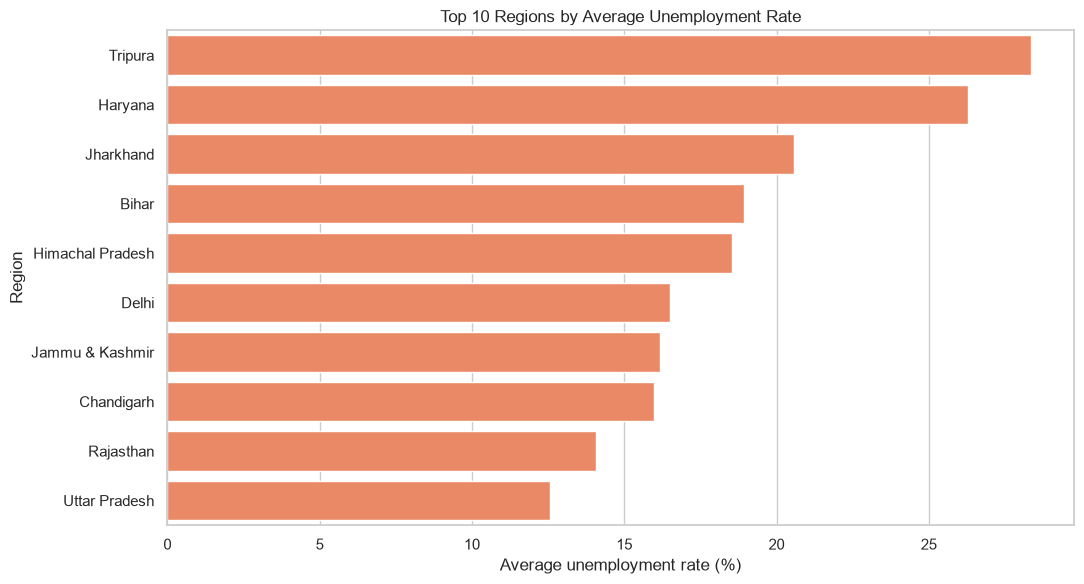

,region,unemployment_rate
24,Tripura,28.350357
8,Haryana,26.283214
11,Jharkhand,20.585000
2,Bihar,18.918214
9,Himachal Pradesh,18.540357
5,Delhi,16.495357
10,Jammu & Kashmir,16.188571
3,Chandigarh,15.991667
20,Rajasthan,14.058214
25,Uttar Pradesh,12.551429


Observation: The chart ranks the ten highest regional averages. Use the time-series charts as well, because an average can hide short-lived spikes.


In [9]:
top10 = region_avg.head(10)
plt.figure(figsize=(11, 6))
sns.barplot(data=top10, x="unemployment_rate", y="region", color="coral")
plt.title("Top 10 Regions by Average Unemployment Rate")
plt.xlabel("Average unemployment rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_10_regions.png", dpi=150)
plt.show()
display(top10)
print("Observation: The chart ranks the ten highest regional averages. Use the time-series charts as well, because an average can hide short-lived spikes.")

## 8. Correlation heatmap
The source dataset has an **employed-person estimate**, not an employment-rate percentage. Therefore, the heatmap uses an explicitly derived implied employment-to-population ratio, alongside unemployment and labour participation rates. Correlation does not establish causation.

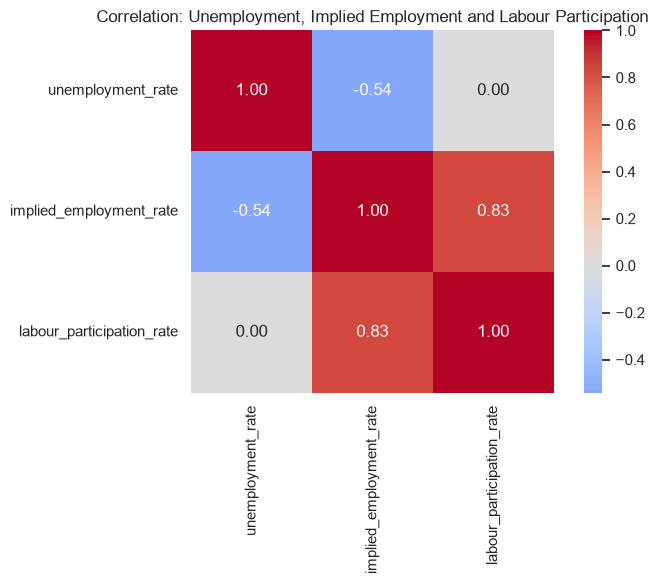

,unemployment_rate,implied_employment_rate,labour_participation_rate
unemployment_rate,1.000000,-0.541232,0.002558
implied_employment_rate,-0.541232,1.000000,0.829870
labour_participation_rate,0.002558,0.829870,1.000000


Observation: Correlation describes the strength and direction of association, not cause and effect. The employment-rate measure is derived, not directly provided by the source.


In [10]:
corr_columns = [
    "unemployment_rate",
    "implied_employment_rate",
    "labour_participation_rate"
]
correlation = df[corr_columns].corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f", square=True)
plt.title("Correlation: Unemployment, Implied Employment and Labour Participation")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "correlation_heatmap.png", dpi=150)
plt.show()
display(correlation)
print("Observation: Correlation describes the strength and direction of association, not cause and effect. The employment-rate measure is derived, not directly provided by the source.")

## 9. Pre-COVID vs post-COVID comparison
For this descriptive analysis, **pre-COVID** means dates before 1 March 2020 and **post-COVID** means dates from 1 March 2020 onward. This is a practical time split, not a claim that the pandemic began on that exact date.

,period,mean_unemployment_rate,mean_implied_employment_rate,mean_labour_participation_rate,observations
0,Post-COVID (Mar 2020 onward),17.774363,32.414147,39.330049,204
1,Pre-COVID (before Mar 2020),9.509534,39.577426,43.886119,536


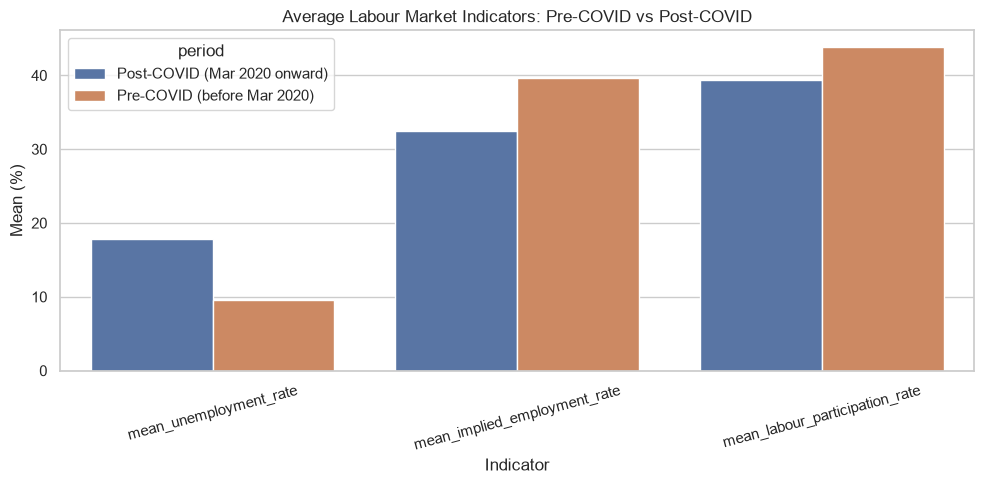

Observation: Post-COVID mean unemployment is 8.26 percentage points higher than pre-COVID mean in this dataset. This descriptive comparison does not prove that COVID alone caused the difference.


In [11]:
df["period"] = np.where(
    df["date"] < COVID_CUTOFF,
    "Pre-COVID (before Mar 2020)",
    "Post-COVID (Mar 2020 onward)"
)
comparison = (
    df.groupby("period", as_index=False)
      .agg(
          mean_unemployment_rate=("unemployment_rate", "mean"),
          mean_implied_employment_rate=("implied_employment_rate", "mean"),
          mean_labour_participation_rate=("labour_participation_rate", "mean"),
          observations=("unemployment_rate", "size")
      )
)
display(comparison)
comparison.to_csv(OUTPUT_DIR / "pre_post_covid_summary.csv", index=False)

plot_data = comparison.melt(
    id_vars="period",
    value_vars=[
        "mean_unemployment_rate",
        "mean_implied_employment_rate",
        "mean_labour_participation_rate"
    ],
    var_name="metric",
    value_name="mean_percent"
)
plt.figure(figsize=(10, 5))
sns.barplot(data=plot_data, x="metric", y="mean_percent", hue="period")
plt.title("Average Labour Market Indicators: Pre-COVID vs Post-COVID")
plt.xlabel("Indicator")
plt.ylabel("Mean (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pre_post_covid_comparison.png", dpi=150)
plt.show()

period_means = comparison.set_index("period")
pre_label = "Pre-COVID (before Mar 2020)"
post_label = "Post-COVID (Mar 2020 onward)"
if pre_label in period_means.index and post_label in period_means.index:
    difference = (
        period_means.loc[post_label, "mean_unemployment_rate"]
        - period_means.loc[pre_label, "mean_unemployment_rate"]
    )
    direction = "higher" if difference > 0 else "lower"
    print(
        f"Observation: Post-COVID mean unemployment is {abs(difference):.2f} "
        f"percentage points {direction} than pre-COVID mean in this dataset. "
        "This descriptive comparison does not prove that COVID alone caused the difference."
    )
else:
    print("Both periods are not represented in this dataset; a pre-/post-COVID comparison cannot be calculated.")

## 10. Final findings – complete after running with the real dataset

Use the numeric results printed above to write 4–6 sentences in your own words:
1. Which region has the highest average unemployment rate?
2. Which month has the highest overall average?
3. How did the three selected regions differ over time?
4. What do the correlations suggest (without claiming causation)?
5. How did the mean unemployment rate differ between the two periods?
6. What limitations should readers keep in mind (sample coverage, averages, derived employment-rate measure)?

**Submission reminder:** Run all cells with the real Kaggle CSV, save the notebook with outputs, and add screenshots. Do not present synthetic/sample results as findings.